# 07 — Klasifikasi SVM Enam Kelas dan Analisis Sensitivitas Fitur

## Ringkasan utama

Notebook ini mendokumentasikan **klasifikasi tingkat citra (*image-level*) enam kelas** pada dataset EBHI-SEG menggunakan *Support Vector Machine* (SVM) dengan pemisahan ketat *train* (`1.535` citra, `247` grup) dan *validation* (`372` citra, `53` grup).

Empat pertanyaan utama diuji:

1. **Perbandingan set fitur kanonik (`A`, `B`, `C`) pada konfigurasi segmentasi terpilih `k4_M0`:** apakah penggabungan fitur *appearance* seluruh piksel (**Set A**, 10 fitur) dan morfologi *mask* prediksi (**Set B**, 19 fitur) menjadi **Set C** (29 fitur) meningkatkan pemisahan enam kategori diagnostik?
2. **Pengaruh hiperparameter dan *class weighting*:** bagaimana pilihan *kernel* (`linear` vs `rbf`), parameter regularisasi `C`, lebar kernel `gamma`, serta `class_weight` (`none` vs `balanced`) memengaruhi keseimbangan performa antara tiga kategori mayoritas (`85,2%` data *train*) dan tiga kategori minoritas (`14,8%` data *train`)?
3. **Sensitivitas pemasking fitur warna/tekstur (`A_seg` dan `C_seg`):** apakah membatasi perhitungan CIE Lab dan GLCM hanya pada piksel *foreground* `k4_M0` memperbaiki performa dibanding menghitungnya pada seluruh bidang citra?
4. **Sensitivitas terhadap komparator segmentasi hulu (`otsu_M0`, `otsu_M2`, `k4_M0`, `k4_M1`):** apakah metode segmentasi dengan *Dice overlap* tertinggi (`k4_M0`) juga menghasilkan deskriptor morfologi paling diskriminatif untuk klasifikasi hilir?

**Batas ilmiah:** *standarisasi fitur* (`StandardScaler`), validasi silang *5-fold StratifiedGroupKFold*, dan pelatihan model hanya menggunakan subset `train`. Pemilihan model dilakukan pada `val` menggunakan metrik utama **Macro F1** (bobot sama lintas enam kategori). Subset *held-out* `test` (`319` citra) **tidak disentuh sama sekali** (`0` citra `test` dievaluasi).

## Konteks, kontrak ilmiah, dan artefak kanonik

### Aturan yang dipertahankan dari tahap 01–06

- **Otoritas kohort:** `data/metadata/split_manifest.csv` diverifikasi secara *raw-byte* (`ceeba8e2...`). Evaluasi dilakukan pada tingkat citra (*image-level*) karena terdapat 74 `group_id` multi-kategori, namun seluruh skema validasi (*5-fold StratifiedGroupKFold* pada `train` maupun evaluasi `val`) tetap *group-disjoint* (`0` grup bocor antar-*split*).
- **Jalur utama (*primary track*):** sesuai kontrak serah-terima tahap 06, konfigurasi segmentasi utama adalah `k4_M0` dengan tiga kandidat set fitur utama: **Set A** (10 fitur warna Lab + GLCM seluruh piksel), **Set B** (19 fitur morfologi *mask* prediksi `k4_M0`), dan **Set C** (`A + B`, 29 fitur).
- **Jalur sensitivitas:**
  1. `A_seg` (10 fitur) dan `C_seg` (29 fitur) pada *mask* `k4_M0`.
  2. Set `B` dan Set `C` lintas empat komparator segmentasi beku (`otsu_M0`, `otsu_M2`, `k4_M0`, `k4_M1`).
- **Aturan pemilihan model (*selection rule*):** berurutan berdasarkan `val_macro_f1` (4 desimal) $\rightarrow$ `val_balanced_accuracy` (4 desimal) $\rightarrow$ `val_accuracy` (4 desimal) $\rightarrow$ `cv_macro_f1` (4 desimal) $\rightarrow$ *kernel* lebih sederhana (`linear` di atas `rbf`) $\rightarrow$ regularisasi lebih kuat (`C` lebih kecil).
- **Portabilitas C++:** setiap model terpilih pada jalur utama diekspor ke `models/svm_k4_M0_*.json` beserta parameter `StandardScaler`, *support vectors*, koefisien dual, dan *intercept* untuk inferensi *one-vs-one* (OVO) mandiri tanpa ketergantungan *runtime* `scikit-learn`.

In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

from ebhi_dip import (
    ALL_FEATURE_SETS,
    DECISION_PARITY_ATOL,
    DEFAULT_FEATURE_METHODS,
    EXPECTED_CATEGORIES,
    PRIMARY_FEATURE_METHOD,
    PRIMARY_FEATURE_SETS,
     apply_standard_scaler,
    classification_metrics,
    configure_notebook_style,
    confusion_matrix_table,
    export_svm_artifact,
    feature_columns_for_set,
    find_project_root,
    finish_figure,
    fit_standard_scaler,
    fit_svm_model,
    load_classification_feature_frame,
    load_split_manifest,
    load_svm_artifact,
    load_validation_results,
    method_label,
    per_category_classification_table,
    predict_from_svm_artifact,
    selection_key_for_svm,
    sha256_bytes,
    summarize_validation_methods,
    verify_frozen_split,
    verify_svm_artifact_parity,
)

PROJECT_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
PRIMARY_METHOD = PRIMARY_FEATURE_METHOD
FEATURE_METHODS = DEFAULT_FEATURE_METHODS

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
CLS_DIR = ROOT / "results/classification"
FEATURE_DIR = ROOT / "results/features"
MODELS_DIR = ROOT / "models"
configure_notebook_style()

protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "feature_manifest": FEATURE_DIR / "feature_manifest.json",
    "segmented_manifest": FEATURE_DIR / f"feature_manifest_segmented_{PRIMARY_METHOD}.json",
    "appearance": FEATURE_DIR / "appearance.csv",
    "segmented_appearance": FEATURE_DIR / f"appearance_segmented_{PRIMARY_METHOD}.csv",
    "segmented_features": FEATURE_DIR / f"features_{PRIMARY_METHOD}_segmented.csv",
    "cls_manifest": CLS_DIR / "classification_manifest.json",
    "svm_grid": CLS_DIR / "svm_grid_results.csv",
    "svm_summary": CLS_DIR / "svm_selected_summary.csv",
    "svm_per_cat": CLS_DIR / "svm_per_category_val.csv",
    "svm_comp": CLS_DIR / "svm_comparator_sensitivity.csv",
    "svm_val_pred": CLS_DIR / "svm_val_predictions.csv",
    "model_A": MODELS_DIR / f"svm_{PRIMARY_METHOD}_A.json",
    "model_B": MODELS_DIR / f"svm_{PRIMARY_METHOD}_B.json",
    "model_C": MODELS_DIR / f"svm_{PRIMARY_METHOD}_C.json",
    "model_selected": MODELS_DIR / f"svm_{PRIMARY_METHOD}_selected.json",
}
protected_files.update(
    {f"features_{m}": FEATURE_DIR / f"features_{m}.csv" for m in FEATURE_METHODS}
)
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": [
                "Python",
                "NumPy",
                "pandas",
                "scikit-learn",
                "Matplotlib",
                "Konfigurasi segmentasi utama",
                "Set fitur utama",
                "Set fitur sensitivitas",
            ],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                sklearn.__version__,
                matplotlib.__version__,
                PRIMARY_METHOD,
                ", ".join(PRIMARY_FEATURE_SETS),
                "A_seg, C_seg + 4 komparator segmentasi",
            ],
        }
    )
)

,komponen,nilai
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,scikit-learn,1.9.1
4,Matplotlib,3.11.2
5,Konfigurasi segmentasi utama,k4_M0
6,Set fitur utama,"A, B, C"
7,Set fitur sensitivitas,"A_seg, C_seg + 4 komparator segmentasi"


## 1. Memuat artefak klasifikasi, verifikasi isolasi *split*, dan ketimpangan kelas

Sel berikut memuat hasil evaluasi SVM kanonik dari `results/classification/`, memverifikasi bahwa hanya `train` (`1.535` citra, `247` grup) dan `val` (`372` citra, `53` grup) yang diakses (`test_images_touched == 0`), serta memeriksa proporsi keenam kategori diagnostik.

In [2]:
cls_manifest = json.loads(protected_files["cls_manifest"].read_text(encoding="utf-8"))
grid_df = pd.read_csv(protected_files["svm_grid"])
summary_df = pd.read_csv(protected_files["svm_summary"])
per_cat_df = pd.read_csv(protected_files["svm_per_cat"])
comp_df = pd.read_csv(protected_files["svm_comp"])
val_pred_df = pd.read_csv(protected_files["svm_val_pred"])

train_primary, val_primary, loaded_sha = load_classification_feature_frame(
    ROOT, method=PRIMARY_METHOD, segmented=False
)
train_seg, val_seg, _ = load_classification_feature_frame(
    ROOT, method=PRIMARY_METHOD, segmented=True
)

assert loaded_sha == SPLIT_SHA == cls_manifest["split_sha256"]
assert cls_manifest["cohort_counts"]["test_images_touched"] == 0
assert set(val_pred_df["split"]) == {"val"}
assert len(train_primary) == 1535 and len(val_primary) == 372

class_balance = pd.DataFrame(
    {
        "train_images": train_primary["category"].value_counts().reindex(EXPECTED_CATEGORIES),
        "train_groups": train_primary.groupby("category", observed=True)["group_id"]
        .nunique()
        .reindex(EXPECTED_CATEGORIES),
        "val_images": val_primary["category"].value_counts().reindex(EXPECTED_CATEGORIES),
        "val_groups": val_primary.groupby("category", observed=True)["group_id"]
        .nunique()
        .reindex(EXPECTED_CATEGORIES),
    }
)
class_balance["train_share_pct"] = 100.0 * class_balance["train_images"] / len(train_primary)
class_balance["val_share_pct"] = 100.0 * class_balance["val_images"] / len(val_primary)
class_balance.loc["TOTAL"] = [
    int(class_balance["train_images"].sum()),
    int(train_primary["group_id"].nunique()),
    int(class_balance["val_images"].sum()),
    int(val_primary["group_id"].nunique()),
    100.0,
    100.0,
]

display(
    class_balance.style.format(
        {
            "train_images": "{:.0f}",
            "train_groups": "{:.0f}",
            "val_images": "{:.0f}",
            "val_groups": "{:.0f}",
            "train_share_pct": "{:.2f}%",
            "val_share_pct": "{:.2f}%",
        }
    )
)
print(
    f"Rasio kelas terbesar vs terkecil: train = {540/42:.1f}x (Adenocarcinoma 540 vs Serrated adenoma 42) | "
    f"val = {131/8:.1f}x (Adenocarcinoma 131 vs Serrated adenoma 8)."
)

,train_images,train_groups,val_images,val_groups,train_share_pct,val_share_pct
category,,,,,,
Adenocarcinoma,540,75,131,15,35.18%,35.22%
High-grade IN,131,28,20,5,8.53%,5.38%
Low-grade IN,444,101,107,21,28.93%,28.76%
Normal,54,11,10,3,3.52%,2.69%
Polyp,324,81,96,21,21.11%,25.81%
Serrated adenoma,42,10,8,2,2.74%,2.15%
TOTAL,1535,247,372,53,100.00%,100.00%


Rasio kelas terbesar vs terkecil: train = 12.9x (Adenocarcinoma 540 vs Serrated adenoma 42) | val = 16.4x (Adenocarcinoma 131 vs Serrated adenoma 8).


### Temuan 1 — ketimpangan ukuran kategori dan implikasi metrik

- Tiga kategori mayoritas (`Adenocarcinoma`, `Low-grade IN`, `Polyp`) mencakup **85,21% citra `train`** (`1.308 / 1.535`) dan **89,78% citra `val`** (`334 / 372`).
- Sebaliknya, tiga kategori minoritas (`High-grade IN`, `Normal`, `Serrated adenoma`) hanya mencakup **14,79% citra `train`** dan **10,22% citra `val`** (hanya `8` citra `Serrated adenoma` dan `10` citra `Normal` di `val`).
- Akibat ketimpangan hingga **16,4×** pada `val`, *overall accuracy* didominasi oleh tiga kategori besar. Oleh karena itu, **Macro F1** (rerata F1 berbobot sama lintas enam kategori) dan **Balanced Accuracy** (rerata *recall* berbobot sama lintas enam kategori) wajib menjadi tolok ukur utama pendamping *accuracy*.

## 2. Perbandingan set fitur kanonik (`A`, `B`, `C`) dan `A_seg`/`C_seg` pada `k4_M0`

Bagian ini membandingkan performa lima set fitur pada konfigurasi segmentasi utama `k4_M0` antara *baseline* RBF standar (`C=1.0, gamma='scale', class_weight='none'`) dan konfigurasi terbaik hasil seleksi (`selected_best`).

,track,feature_set,n_features,model_variant,kernel,class_weight,C,gamma,cv_macro_f1,cv_balanced_accuracy,cv_accuracy,val_macro_f1,val_balanced_accuracy,val_accuracy,val_weighted_f1
0,primary_k4_M0,A,10,default_rbf,rbf,none,1.0,scale,0.3182,0.3177,0.5186,0.2732,0.2838,0.5027,0.4837
1,primary_k4_M0,A,10,selected_best,rbf,balanced,1.0,scale,0.3185,0.3490,0.3935,0.3420,0.4843,0.3978,0.4351
2,primary_k4_M0,B,19,default_rbf,rbf,none,1.0,scale,0.2362,0.2556,0.4638,0.2333,0.2434,0.4409,0.4208
3,primary_k4_M0,B,19,selected_best,rbf,none,3.0,0.1,0.2457,0.2580,0.4586,0.2608,0.2648,0.4651,0.4483
4,primary_k4_M0,C,29,default_rbf,rbf,none,1.0,scale,0.3083,0.3163,0.5381,0.2944,0.3083,0.5457,0.5214
5,primary_k4_M0,C,29,selected_best,rbf,none,10.0,0.01,0.3661,0.3552,0.5498,0.3625,0.3486,0.5430,0.5313
6,sensitivity_A_seg_C_seg,A_seg,10,default_rbf,rbf,none,1.0,scale,0.3223,0.3238,0.5218,0.2733,0.2868,0.5054,0.4815
7,sensitivity_A_seg_C_seg,A_seg,10,selected_best,linear,none,10.0,scale,0.3024,0.3154,0.5107,0.2897,0.2978,0.5296,0.5150
8,sensitivity_A_seg_C_seg,C_seg,29,default_rbf,rbf,none,1.0,scale,0.3274,0.3347,0.5609,0.2762,0.2876,0.5108,0.4895
9,sensitivity_A_seg_C_seg,C_seg,29,selected_best,rbf,none,10.0,scale,0.3479,0.3461,0.5309,0.3182,0.3249,0.5188,0.5132


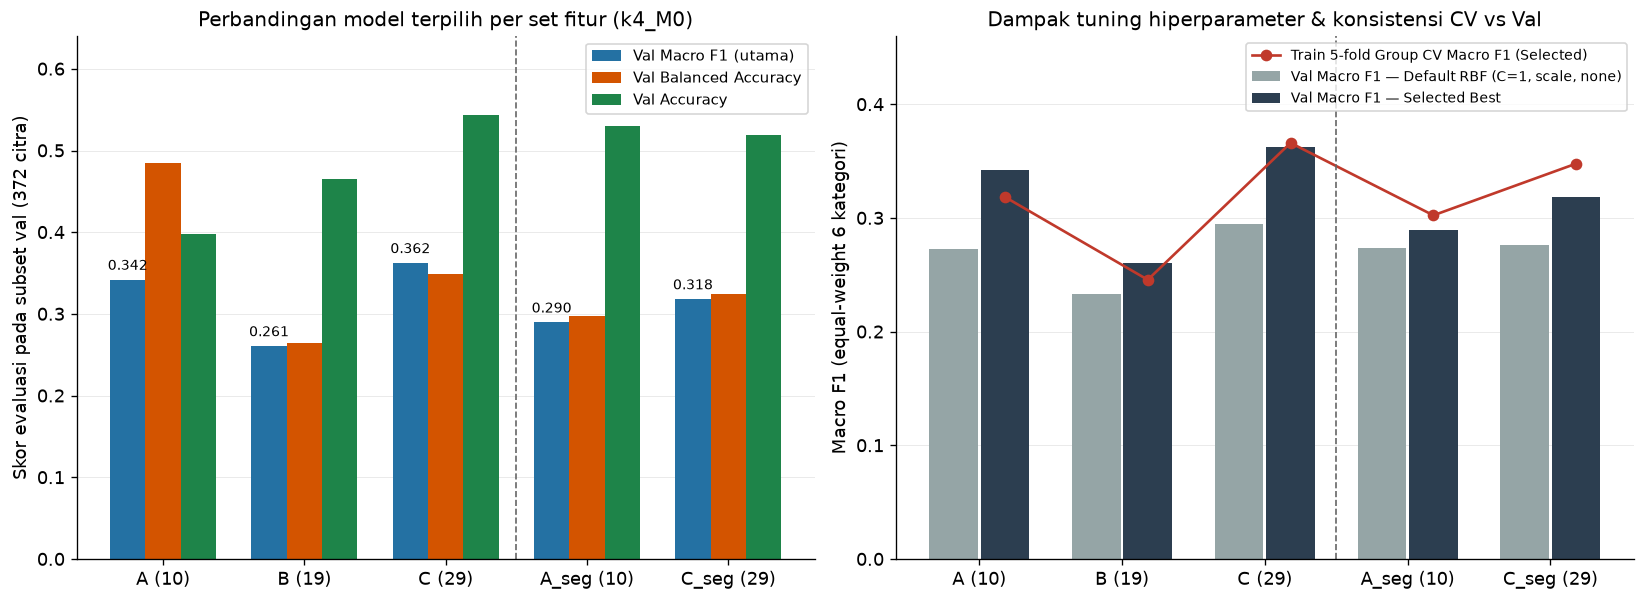

In [3]:
display_cols = [
    "track",
    "feature_set",
    "n_features",
    "model_variant",
    "kernel",
    "class_weight",
    "C",
    "gamma",
    "cv_macro_f1",
    "cv_balanced_accuracy",
    "cv_accuracy",
    "val_macro_f1",
    "val_balanced_accuracy",
    "val_accuracy",
    "val_weighted_f1",
]
display(
    summary_df[display_cols].style.format(
        {
            "C": "{:.1f}",
            "cv_macro_f1": "{:.4f}",
            "cv_balanced_accuracy": "{:.4f}",
            "cv_accuracy": "{:.4f}",
            "val_macro_f1": "{:.4f}",
            "val_balanced_accuracy": "{:.4f}",
            "val_accuracy": "{:.4f}",
            "val_weighted_f1": "{:.4f}",
        }
    )
)

selected_only = summary_df.loc[summary_df["model_variant"].eq("selected_best")].set_index("feature_set")
default_only = summary_df.loc[summary_df["model_variant"].eq("default_rbf")].set_index("feature_set")

fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.9), layout="constrained")
sets_order = list(ALL_FEATURE_SETS)
x = np.arange(len(sets_order))
width = 0.25

axes[0].bar(
    x - width,
    selected_only.loc[sets_order, "val_macro_f1"],
    width=width,
    color="#2471A3",
    label="Val Macro F1 (utama)",
)
axes[0].bar(
    x,
    selected_only.loc[sets_order, "val_balanced_accuracy"],
    width=width,
    color="#D35400",
    label="Val Balanced Accuracy",
)
axes[0].bar(
    x + width,
    selected_only.loc[sets_order, "val_accuracy"],
    width=width,
    color="#1E8449",
    label="Val Accuracy",
)
for idx, s_name in enumerate(sets_order):
    val_f1 = float(selected_only.loc[s_name, "val_macro_f1"])
    axes[0].text(idx - width, val_f1 + 0.008, f"{val_f1:.3f}", ha="center", va="bottom", fontsize=8.3)
axes[0].axvline(2.5, color="#666666", linestyle="--", linewidth=1.0)
axes[0].set_xticks(x, ["A (10)", "B (19)", "C (29)", "A_seg (10)", "C_seg (29)"])
axes[0].set_ylim(0, 0.64)
axes[0].set_ylabel("Skor evaluasi pada subset val (372 citra)")
axes[0].set_title("Perbandingan model terpilih per set fitur (k4_M0)")
axes[0].legend(frameon=True, fontsize=8.8, loc="upper right")
axes[0].grid(axis="y", color="#EAEAEA", linewidth=0.6)

axes[1].bar(
    x - 0.18,
    default_only.loc[sets_order, "val_macro_f1"],
    width=0.34,
    color="#95A5A6",
    label="Val Macro F1 — Default RBF (C=1, scale, none)",
)
axes[1].bar(
    x + 0.18,
    selected_only.loc[sets_order, "val_macro_f1"],
    width=0.34,
    color="#2C3E50",
    label="Val Macro F1 — Selected Best",
)
axes[1].plot(
    x + 0.18,
    selected_only.loc[sets_order, "cv_macro_f1"],
    color="#C0392B",
    marker="o",
    linewidth=1.6,
    label="Train 5-fold Group CV Macro F1 (Selected)",
)
axes[1].axvline(2.5, color="#666666", linestyle="--", linewidth=1.0)
axes[1].set_xticks(x, ["A (10)", "B (19)", "C (29)", "A_seg (10)", "C_seg (29)"])
axes[1].set_ylim(0, 0.46)
axes[1].set_ylabel("Macro F1 (equal-weight 6 kategori)")
axes[1].set_title("Dampak tuning hiperparameter & konsistensi CV vs Val")
axes[1].legend(frameon=True, fontsize=8.4, loc="upper right")
axes[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

finish_figure(
    fig,
    export_path=(ROOT / "reports/figures/07_feature_set_comparison_k4_M0.png") if EXPORT_FIGURES else None,
)

### Temuan 2 — keunggulan Set C pada `k4_M0` dan evaluasi empiris `A_seg`/`C_seg`

- **Set C (`A + B`, 29 fitur) adalah model terbaik pada jalur utama `k4_M0`:** model terpilih `svm_k4_M0_C` (`rbf, C=10.0, gamma=0.01, class_weight='none'`) mencapai **`val_macro_f1 = 0.3625`**, **`cv_macro_f1 = 0.3661`**, dan **`val_accuracy = 0.5430`** (naik dari *baseline* RBF standar `val_macro_f1 = 0.2944`). Selisih antara *5-fold Group CV* pada `train` (`0.3661`) dan `val` (`0.3625`) hanya `0.0037` poin, menandakan generalisasi lintas-grup yang stabil.
- **Set B (morfologi `k4_M0` saja, 19 fitur) paling lemah (`val_macro_f1 = 0.2608`, `val_accuracy = 0.4651`):** sesuai peringatan diagnostik pada tahap 06, *mask* `k4_M0` menutupi rata-rata 85,34% area citra dengan 49,19% komponen berperimeter nol, sehingga fitur bentuk tunggal tanpa informasi warna/GLCM tidak cukup memisahkan enam kelas. Namun, ketika digabung dengan Set A di dalam Set C, fitur morfologi tetap memberi peningkatan `+0.0204` Macro F1 dan `+0.1452` *accuracy* dibanding model terpilih Set A (`val_macro_f1 = 0.3420`, `val_accuracy = 0.3978`).
- **`A_seg` dan `C_seg` tidak mengungguli `A` dan `C`:** baik pada konfigurasi *default* maupun *tuned*, `A_seg` (`val_macro_f1 = 0.2897`) lebih rendah daripada `A` (`0.3420`), dan `C_seg` (`val_macro_f1 = 0.3182`, `val_accuracy = 0.5188`) lebih rendah daripada `C` (`0.3625`, `val_accuracy = 0.5430`). Membatasi ekstraksi CIE Lab dan GLCM ke dalam *mask* `k4_M0` menghilangkan kontras antara epitel/stroma dan lumen putih (`lab_b_std`, `lab_l_std`, `glcm_contrast` lintas batas lumen) yang justru informatif untuk membedakan arsitektur kelenjar.

## 3. Eksplorasi hiperparameter dan *trade-off* `class_weight` (`none` vs `balanced`)

Untuk memahami bagaimana *kernel*, regularisasi `C`, dan pembobotan kelas bekerja pada data yang timpang, bagian ini membandingkan profil *grid search* (`32` konfigurasi per set fitur) antara `class_weight='none'` dan `class_weight='balanced'`.

,feature_set,class_weight,kernel,C,gamma,cv_macro_f1,val_macro_f1,val_balanced_accuracy,val_accuracy,val_macro_precision
0,A,balanced,rbf,1.0,scale,0.3185,0.3420,0.4843,0.3978,0.3730
1,A,none,rbf,10.0,scale,0.3346,0.3140,0.3207,0.4973,0.3256
2,B,balanced,rbf,10.0,scale,0.2847,0.2490,0.2790,0.3333,0.2719
3,B,none,rbf,3.0,0.1,0.2457,0.2608,0.2648,0.4651,0.2848
4,C,balanced,rbf,3.0,scale,0.3650,0.3386,0.4018,0.4462,0.3502
5,C,none,rbf,10.0,0.01,0.3661,0.3625,0.3486,0.5430,0.5227


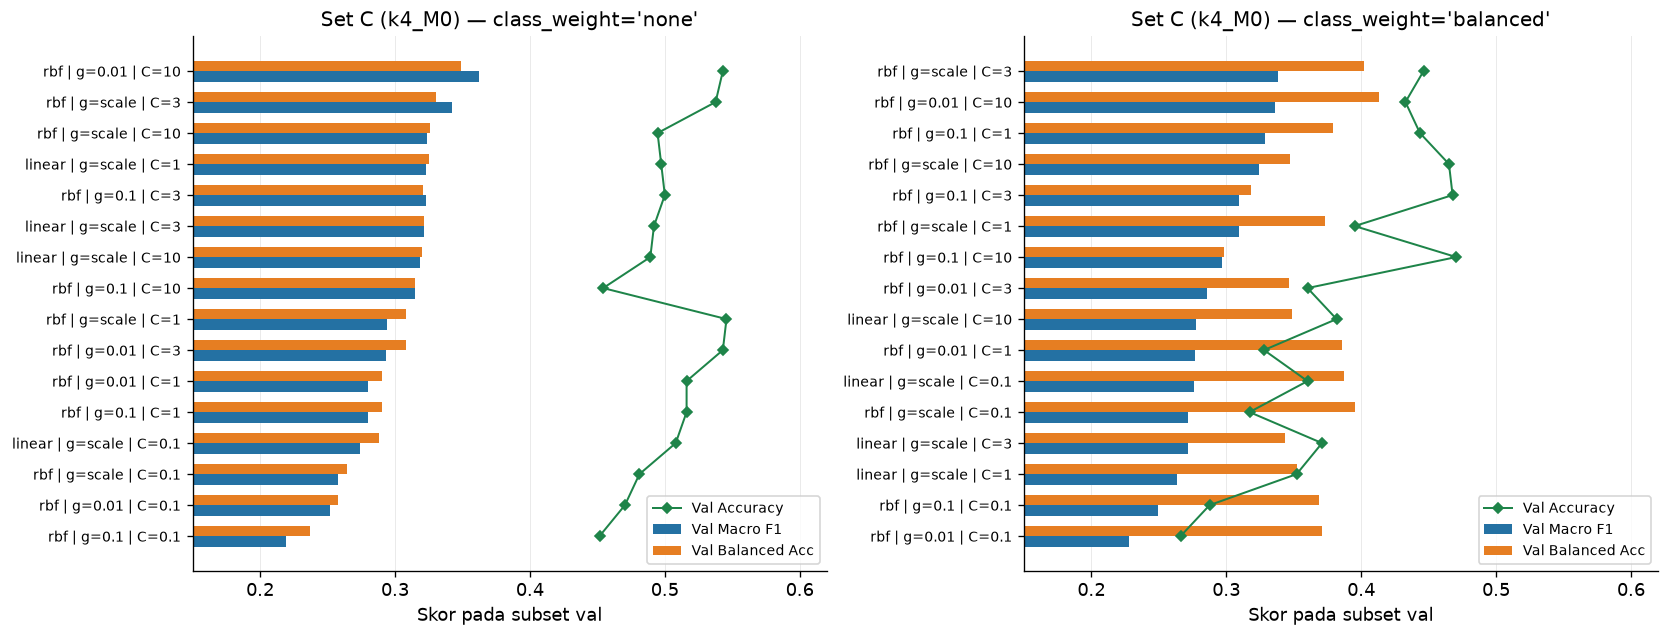

In [4]:
cw_comparison = (
    grid_df.loc[grid_df["feature_set"].isin(["A", "B", "C"])]
    .sort_values(
        ["val_macro_f1", "val_balanced_accuracy", "val_accuracy", "cv_macro_f1"],
        ascending=False,
    )
    .groupby(["feature_set", "class_weight"], observed=True)
    .first()
    .reset_index()
)
display(
    cw_comparison[
        [
            "feature_set",
            "class_weight",
            "kernel",
            "C",
            "gamma",
            "cv_macro_f1",
            "val_macro_f1",
            "val_balanced_accuracy",
            "val_accuracy",
            "val_macro_precision",
        ]
    ].style.format(
        {
            "C": "{:.1f}",
            "cv_macro_f1": "{:.4f}",
            "val_macro_f1": "{:.4f}",
            "val_balanced_accuracy": "{:.4f}",
            "val_accuracy": "{:.4f}",
            "val_macro_precision": "{:.4f}",
        }
    )
)

grid_c = grid_df.loc[grid_df["feature_set"].eq("C")].copy()
grid_c["spec_label"] = (
    grid_c["kernel"]
    + " | g="
    + grid_c["gamma"].astype(str)
    + " | C="
    + grid_c["C"].map(lambda v: f"{v:g}")
)

fig_hp, axes_hp = plt.subplots(1, 2, figsize=(13.8, 5.2), layout="constrained")
for cw_idx, (cw_val, ax_title) in enumerate(
    [
        ("none", "Set C (k4_M0) — class_weight='none'"),
        ("balanced", "Set C (k4_M0) — class_weight='balanced'"),
    ]
):
    sub = grid_c.loc[grid_c["class_weight"].eq(cw_val)].sort_values(
        ["val_macro_f1", "val_balanced_accuracy"], ascending=True
    )
    y_pos = np.arange(len(sub))
    axes_hp[cw_idx].barh(
        y_pos - 0.17,
        sub["val_macro_f1"],
        height=0.34,
        color="#2471A3",
        label="Val Macro F1",
    )
    axes_hp[cw_idx].barh(
        y_pos + 0.17,
        sub["val_balanced_accuracy"],
        height=0.34,
        color="#E67E22",
        label="Val Balanced Acc",
    )
    axes_hp[cw_idx].plot(
        sub["val_accuracy"],
        y_pos,
        color="#1E8449",
        marker="D",
        markersize=4.2,
        linewidth=1.2,
        label="Val Accuracy",
    )
    axes_hp[cw_idx].set_yticks(y_pos, sub["spec_label"], fontsize=8.2)
    axes_hp[cw_idx].set_xlim(0.15, 0.62)
    axes_hp[cw_idx].set_xlabel("Skor pada subset val")
    axes_hp[cw_idx].set_title(ax_title)
    axes_hp[cw_idx].grid(axis="x", color="#EAEAEA", linewidth=0.6)
    axes_hp[cw_idx].legend(frameon=True, fontsize=8.3, loc="lower right")

finish_figure(
    fig_hp,
    export_path=(ROOT / "reports/figures/07_hyperparameter_tradeoff_set_C.png") if EXPORT_FIGURES else None,
)

### Temuan 3 — *trade-off* `class_weight='balanced'` terhadap presisi kelas minoritas

- **Observasi:** pemberian bobot balik frekuensi kelas (`class_weight='balanced'`) secara konsisten menaikkan **`val_balanced_accuracy`** (pada Set A naik dari `0.3207` menjadi `0.4843`; pada Set C naik dari `0.3486` menjadi `0.4135`), tetapi menurunkan **`val_accuracy`** secara tajam (pada Set A turun dari `0.4973` ke `0.3978`; pada Set C turun dari `0.5430` ke `0.4328`).
- **Penyebab mekanis:** karena fitur warna dan tekstur kelenjar antar-kategori memiliki tumpang tindih di ruang berdimensi rendah (10–29 fitur), bobot penalti besar pada kelas langka (`Serrated adenoma` bobot $\approx 6.1\times$, `Normal` bobot $\approx 4.7\times$) menggeser *hyperplane* OVO sehingga puluhan sampel `Adenocarcinoma` dan `Low-grade IN` diprediksi sebagai kelas minoritas. *Recall* kelas langka naik, tetapi *precision* kelas langka jatuh (misalnya pada Set A `balanced`, 88 citra `val` diprediksi sebagai `Serrated adenoma` padahal *support* aslinya hanya 8 citra; `precision = 5.68%`).
- **Implikasi seleksi:** pada Set C, konfigurasi `rbf, C=10.0, gamma=0.01, class_weight='none'` mampu membuka batas keputusan bagi keenam kelas (`val_macro_precision = 0.5227`, `val_macro_f1 = 0.3625`) tanpa mengorbankan akurasi kelas mayoritas (`val_accuracy = 0.5430`).

## 4. Performa per kategori diagnostik dan *confusion matrix* pada `val`

Bagian ini memeriksa rincian *precision*, *recall*, *F1*, dan pola salah klasifikasi antar-kategori pada 372 citra validasi untuk model terpilih **Set A**, **Set B**, dan **Set C** (`k4_M0`).

,support_val,A_pred,A_recall,A_f1,B_pred,B_recall,B_f1,C_pred,C_precision,C_recall,C_f1
category,,,,,,,,,,,
Adenocarcinoma,131,52,0.1908,0.2732,137,0.5267,0.5149,113,0.5664,0.4885,0.5246
High-grade IN,20,30,0.2500,0.2000,4,0.0500,0.0833,4,0.2500,0.0500,0.0833
Low-grade IN,107,89,0.4673,0.5102,150,0.5327,0.4436,163,0.4479,0.6822,0.5407
Normal,10,43,0.8000,0.3019,1,0.0000,0.0000,8,0.1250,0.1000,0.1111
Polyp,96,70,0.5729,0.6627,80,0.4792,0.5227,83,0.7470,0.6458,0.6927
Serrated adenoma,8,88,0.6250,0.1042,0,0.0000,0.0000,1,1.0000,0.1250,0.2222


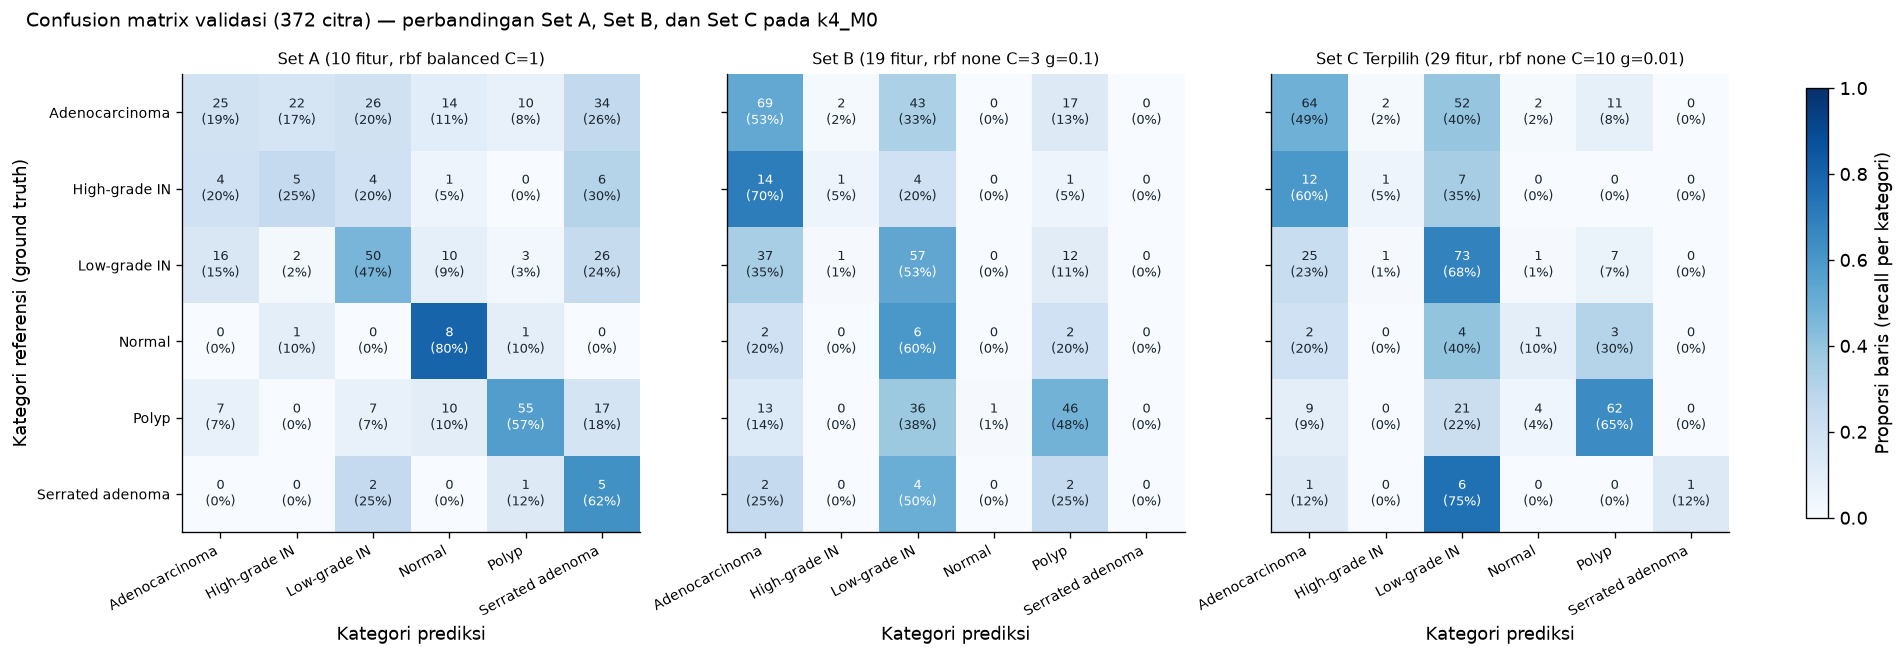

In [5]:
per_cat_selected = per_cat_df.loc[
    per_cat_df["method"].eq(PRIMARY_METHOD)
    & per_cat_df["model_variant"].eq("selected_best")
    & per_cat_df["feature_set"].isin(["A", "B", "C"])
].copy()

pivot_cat = per_cat_selected.pivot(
    index="category",
    columns="feature_set",
    values=["support", "predicted_count", "precision", "recall", "f1"],
).reindex(list(EXPECTED_CATEGORIES))

summary_cat_table = pd.DataFrame(
    {
        "support_val": per_cat_selected.loc[per_cat_selected["feature_set"].eq("C")]
        .set_index("category")
        .reindex(EXPECTED_CATEGORIES)["support"],
        "A_pred": pivot_cat[("predicted_count", "A")].astype(int),
        "A_recall": pivot_cat[("recall", "A")],
        "A_f1": pivot_cat[("f1", "A")],
        "B_pred": pivot_cat[("predicted_count", "B")].astype(int),
        "B_recall": pivot_cat[("recall", "B")],
        "B_f1": pivot_cat[("f1", "B")],
        "C_pred": pivot_cat[("predicted_count", "C")].astype(int),
        "C_precision": pivot_cat[("precision", "C")],
        "C_recall": pivot_cat[("recall", "C")],
        "C_f1": pivot_cat[("f1", "C")],
    }
)
display(
    summary_cat_table.style.format(
        {
            "A_recall": "{:.4f}",
            "A_f1": "{:.4f}",
            "B_recall": "{:.4f}",
            "B_f1": "{:.4f}",
            "C_precision": "{:.4f}",
            "C_recall": "{:.4f}",
            "C_f1": "{:.4f}",
        }
    )
)

category_labels = list(EXPECTED_CATEGORIES)
fig_cm, axes_cm = plt.subplots(1, 3, figsize=(15.8, 5.3), layout="constrained")

for ax, set_name, title_suffix in zip(
    axes_cm,
    ["A", "B", "C"],
    [
        "Set A (10 fitur, rbf balanced C=1)",
        "Set B (19 fitur, rbf none C=3 g=0.1)",
        "Set C Terpilih (29 fitur, rbf none C=10 g=0.01)",
    ],
):
    sub_pred = (
        val_pred_df.loc[
            val_pred_df["method"].eq(PRIMARY_METHOD)
            & val_pred_df["feature_set"].eq(set_name)
            & val_pred_df["model_variant"].eq("selected_best")
        ]
        .sort_values("sample_id")
    )
    cm_counts = confusion_matrix_table(
        sub_pred["category"], sub_pred["predicted_category"], normalize=None
    )
    cm_norm = confusion_matrix_table(
        sub_pred["category"], sub_pred["predicted_category"], normalize="true"
    )
    im = ax.imshow(cm_norm.to_numpy(), cmap="Blues", vmin=0.0, vmax=1.0)
    ax.set_xticks(np.arange(6), category_labels, rotation=28, ha="right", fontsize=8.3)
    ax.set_yticks(np.arange(6), category_labels if set_name == "A" else [], fontsize=8.5)
    if set_name == "A":
        ax.set_ylabel("Kategori referensi (ground truth)")
    ax.set_xlabel("Kategori prediksi")
    ax.set_title(title_suffix, fontsize=9.8)
    ax.grid(False)

    for r_idx in range(6):
        for c_idx in range(6):
            cnt = int(cm_counts.iat[r_idx, c_idx])
            pct = 100.0 * float(cm_norm.iat[r_idx, c_idx])
            text_color = "white" if pct >= 50.0 else "#1B2631"
            ax.text(
                c_idx,
                r_idx,
                f"{cnt}\n({pct:.0f}%)",
                ha="center",
                va="center",
                fontsize=7.5,
                color=text_color,
            )

fig_cm.colorbar(im, ax=axes_cm, shrink=0.82, label="Proporsi baris (recall per kategori)")
fig_cm.suptitle(
    "Confusion matrix validasi (372 citra) — perbandingan Set A, Set B, dan Set C pada k4_M0",
    fontsize=11.5,
    x=0.01,
    ha="left",
)
finish_figure(
    fig_cm,
    export_path=(ROOT / "reports/figures/07_confusion_matrices_A_B_C.png") if EXPORT_FIGURES else None,
)

### Temuan 4 — pola kesalahan antar-kategori histopatologi

- **Kategori dengan pemisahan paling konsisten adalah `Polyp` (`F1 = 0.6927`, `precision = 74,70%`, `recall = 64,58%` pada Set C):** polip memiliki struktur kelenjar bulat teratur dengan stroma yang khas sehingga paling jarang tertukar dengan karsinoma invasif.
- **Kebingungan terbesar terjadi antara `Adenocarcinoma` dan `Low-grade IN`:** pada Set C, 52 dari 131 citra `Adenocarcinoma` (`40%`) diprediksi sebagai `Low-grade IN`, dan 25 dari 107 citra `Low-grade IN` (`23%`) diprediksi sebagai `Adenocarcinoma`. Secara visual, kedua kelas berbagi pewarnaan epitel H&E yang padat ketika hanya diringkas dengan statistik global tingkat citra.
- **Kelas transisi dan kelas minoritas (`High-grade IN`, `Normal`, `Serrated adenoma`):** `High-grade IN` (`n=20`) berada di tengah spektrum displasia sehingga sebagian besar terserap ke `Low-grade IN` atau `Adenocarcinoma`. Tanpa pembobotan kelas, Set B gagal memprediksi satu pun sampel `Normal` dan `Serrated adenoma` (`F1 = 0.0000`), sedangkan penggabungan fitur di Set C mulai memulihkan prediksi benar pada keenam kategori.

## 5. Sensitivitas terhadap empat komparator segmentasi (`otsu_M0`, `otsu_M2`, `k4_M0`, `k4_M1`)

Pada tahap 05, `k4_M0` terpilih karena memiliki *equal-category mean* Dice tertinggi (`0.7761`) dibanding `otsu_M2` (`0.7288`). Namun, tahap 06 menunjukkan bahwa `k4_M0` menghasilkan *mask* yang sangat luas (`foreground_fraction = 0.8534`) dan memiliki 49,19% komponen berperimeter nol. Bagian ini menguji dampak langsung perbedaan karakter *mask* tersebut terhadap akurasi klasifikasi SVM hilir pada **Set B** dan **Set C**.

,method,label,seg_val_dice,mean_fg_fraction,zero_perim_pct,spec_variant,B_val_macro_f1,B_val_accuracy,C_cv_macro_f1,C_val_macro_f1,C_val_balanced_acc,C_val_accuracy
0,otsu_M0,Otsu M0,0.7232,0.5455,32.22%,default_rbf,0.3181,0.5403,0.4025,0.3778,0.3743,0.5968
1,otsu_M0,Otsu M0,0.7232,0.5455,32.22%,primary_tuned_spec,0.3446,0.5699,0.4520,0.3976,0.3998,0.6290
2,otsu_M2,Otsu M2,0.7288,0.5294,0.00%,default_rbf,0.3369,0.5806,0.3762,0.4021,0.3906,0.6075
3,otsu_M2,Otsu M2,0.7288,0.5294,0.00%,primary_tuned_spec,0.3603,0.5806,0.4512,0.4587,0.4557,0.6237
4,k4_M0,"K-means k=4, M0",0.7761,0.8534,49.19%,default_rbf,0.2333,0.4409,0.3083,0.2944,0.3083,0.5457
5,k4_M0,"K-means k=4, M0",0.7761,0.8534,49.19%,primary_tuned_spec,0.2304,0.4328,0.3661,0.3625,0.3486,0.5430
6,k4_M1,"K-means k=4, M1",0.7760,0.8521,0.00%,default_rbf,0.2002,0.4086,0.3193,0.2896,0.3019,0.5403
7,k4_M1,"K-means k=4, M1",0.7760,0.8521,0.00%,primary_tuned_spec,0.2119,0.4301,0.3528,0.3311,0.3310,0.5511


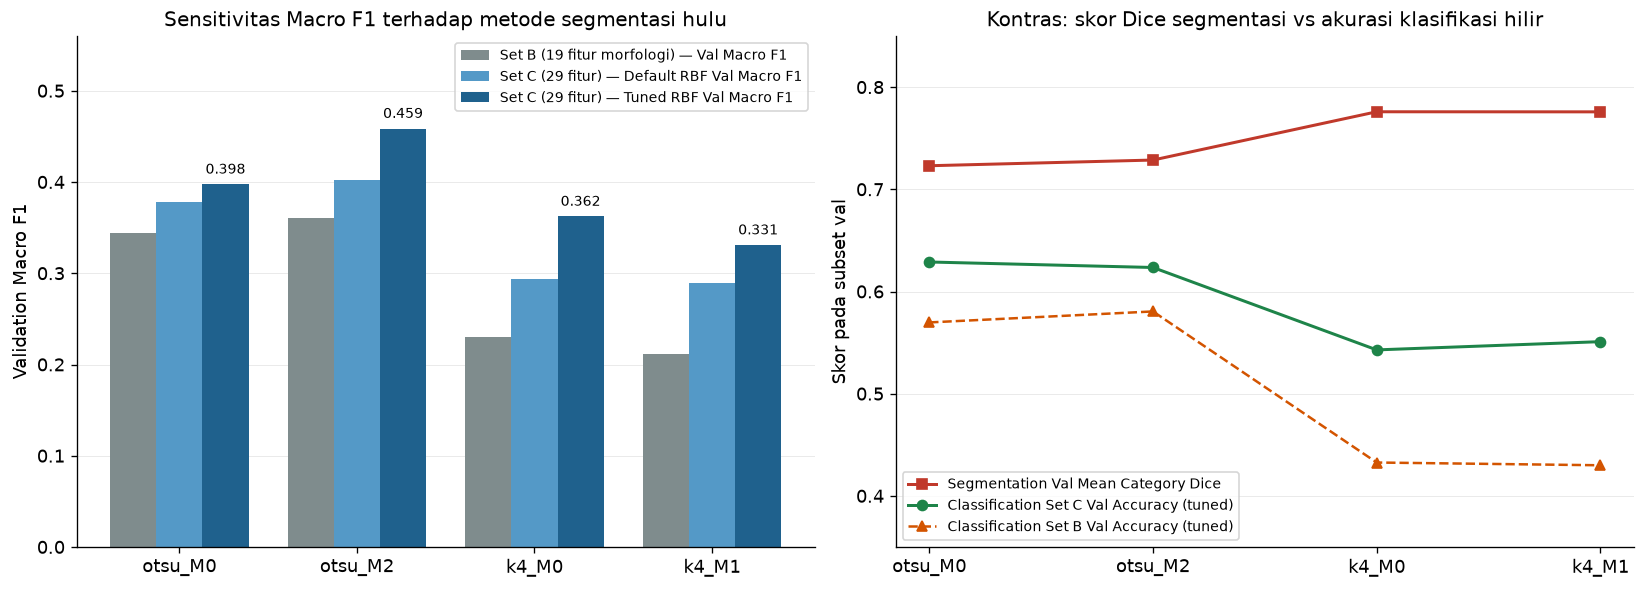

In [6]:
val_seg_df = load_validation_results(ROOT)
seg_summary = summarize_validation_methods(val_seg_df).loc[list(FEATURE_METHODS)]
diag_df = pd.read_csv(FEATURE_DIR / "morphology_diagnostics.csv")
diag_by_method = diag_df.groupby("method", observed=True).agg(
    mean_fg_fraction=("foreground_pixels", lambda s: float(s.mean() / (224 * 224))),
    zero_perim_pct=(
        "zero_perimeter_count",
        lambda s: 100.0 * float(s.sum()) / float(diag_df.loc[s.index, "component_count"].sum()),
    ),
)

comp_pivot = comp_df.pivot_table(
    index=["method", "spec_variant"],
    columns="feature_set",
    values=["cv_macro_f1", "val_macro_f1", "val_balanced_accuracy", "val_accuracy"],
)
comp_summary_rows = []
for m in FEATURE_METHODS:
    for spec_var in ("default_rbf", "primary_tuned_spec"):
        comp_summary_rows.append(
            {
                "method": m,
                "label": method_label(m),
                "seg_val_dice": float(seg_summary.loc[m, "mean_category_dice"]),
                "mean_fg_fraction": float(diag_by_method.loc[m, "mean_fg_fraction"]),
                "zero_perim_pct": float(diag_by_method.loc[m, "zero_perim_pct"]),
                "spec_variant": spec_var,
                "B_val_macro_f1": float(comp_pivot.loc[(m, spec_var), ("val_macro_f1", "B")]),
                "B_val_accuracy": float(comp_pivot.loc[(m, spec_var), ("val_accuracy", "B")]),
                "C_cv_macro_f1": float(comp_pivot.loc[(m, spec_var), ("cv_macro_f1", "C")]),
                "C_val_macro_f1": float(comp_pivot.loc[(m, spec_var), ("val_macro_f1", "C")]),
                "C_val_balanced_acc": float(comp_pivot.loc[(m, spec_var), ("val_balanced_accuracy", "C")]),
                "C_val_accuracy": float(comp_pivot.loc[(m, spec_var), ("val_accuracy", "C")]),
            }
        )
comp_summary_table = pd.DataFrame(comp_summary_rows)
display(
    comp_summary_table.style.format(
        {
            "seg_val_dice": "{:.4f}",
            "mean_fg_fraction": "{:.4f}",
            "zero_perim_pct": "{:.2f}%",
            "B_val_macro_f1": "{:.4f}",
            "B_val_accuracy": "{:.4f}",
            "C_cv_macro_f1": "{:.4f}",
            "C_val_macro_f1": "{:.4f}",
            "C_val_balanced_acc": "{:.4f}",
            "C_val_accuracy": "{:.4f}",
        }
    )
)

tuned_comp = comp_summary_table.loc[comp_summary_table["spec_variant"].eq("primary_tuned_spec")].set_index("method")
default_comp = comp_summary_table.loc[comp_summary_table["spec_variant"].eq("default_rbf")].set_index("method")

fig_sens, axes_sens = plt.subplots(1, 2, figsize=(13.6, 4.8), layout="constrained")
m_pos = np.arange(len(FEATURE_METHODS))
w_bar = 0.26

axes_sens[0].bar(
    m_pos - w_bar,
    tuned_comp.loc[list(FEATURE_METHODS), "B_val_macro_f1"],
    width=w_bar,
    color="#7F8C8D",
    label="Set B (19 fitur morfologi) — Val Macro F1",
)
axes_sens[0].bar(
    m_pos,
    default_comp.loc[list(FEATURE_METHODS), "C_val_macro_f1"],
    width=w_bar,
    color="#5499C7",
    label="Set C (29 fitur) — Default RBF Val Macro F1",
)
axes_sens[0].bar(
    m_pos + w_bar,
    tuned_comp.loc[list(FEATURE_METHODS), "C_val_macro_f1"],
    width=w_bar,
    color="#1F618D",
    label="Set C (29 fitur) — Tuned RBF Val Macro F1",
)
for idx, m_id in enumerate(FEATURE_METHODS):
    v_c = float(tuned_comp.loc[m_id, "C_val_macro_f1"])
    axes_sens[0].text(idx + w_bar, v_c + 0.008, f"{v_c:.3f}", ha="center", va="bottom", fontsize=8.4)
axes_sens[0].set_xticks(m_pos, list(FEATURE_METHODS))
axes_sens[0].set_ylim(0, 0.56)
axes_sens[0].set_ylabel("Validation Macro F1")
axes_sens[0].set_title("Sensitivitas Macro F1 terhadap metode segmentasi hulu")
axes_sens[0].legend(frameon=True, fontsize=8.3, loc="upper right")
axes_sens[0].grid(axis="y", color="#EAEAEA", linewidth=0.6)

axes_sens[1].plot(
    m_pos,
    tuned_comp.loc[list(FEATURE_METHODS), "seg_val_dice"],
    color="#C0392B",
    marker="s",
    linewidth=1.8,
    label="Segmentation Val Mean Category Dice",
)
axes_sens[1].plot(
    m_pos,
    tuned_comp.loc[list(FEATURE_METHODS), "C_val_accuracy"],
    color="#1E8449",
    marker="o",
    linewidth=1.8,
    label="Classification Set C Val Accuracy (tuned)",
)
axes_sens[1].plot(
    m_pos,
    tuned_comp.loc[list(FEATURE_METHODS), "B_val_accuracy"],
    color="#D35400",
    marker="^",
    linestyle="--",
    linewidth=1.5,
    label="Classification Set B Val Accuracy (tuned)",
)
axes_sens[1].set_xticks(m_pos, list(FEATURE_METHODS))
axes_sens[1].set_ylim(0.35, 0.85)
axes_sens[1].set_ylabel("Skor pada subset val")
axes_sens[1].set_title("Kontras: skor Dice segmentasi vs akurasi klasifikasi hilir")
axes_sens[1].legend(frameon=True, fontsize=8.4, loc="lower left")
axes_sens[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

finish_figure(
    fig_sens,
    export_path=(ROOT / "reports/figures/07_comparator_sensitivity.png") if EXPORT_FIGURES else None,
)

### Temuan 5 — diskrepansi antara *Dice overlap* segmentasi dan daya pisah fitur morfologi

- **Observasi kunci:** meskipun `k4_M0` memiliki *equal-category mean* Dice tertinggi pada tahap segmentasi (`0.7761` vs `0.7288` pada `otsu_M2`), fitur morfologi yang diekstrak dari **`otsu_M2` dan `otsu_M0` menghasilkan performa klasifikasi SVM yang jauh lebih tinggi** pada `val` maupun *5-fold Group CV* `train`:
  - Pada **Set B (morfologi saja)**: `otsu_M2` mencapai `val_macro_f1 = 0.3603` dan `val_accuracy = 0.5806`, mengungguli `k4_M0` (`val_macro_f1 = 0.2304`, `val_accuracy = 0.4328`) sebesar **`+0.1300` poin Macro F1** dan **`+14,78%` akurasi**.
  - Pada **Set C (`A + B`)**: `otsu_M2` mencapai **`val_macro_f1 = 0.4587`**, **`val_balanced_accuracy = 0.4557`**, dan **`val_accuracy = 0.6237`** (`cv_macro_f1 = 0.4512`), mengungguli `k4_M0` (`val_macro_f1 = 0.3625`, `val_accuracy = 0.5430`) sebesar **`+0.0963` poin Macro F1** dan **`+8,06%` akurasi**.
- **Penjelasan ilmiah:** *reference mask* EBHI-SEG menandai seluruh wilayah jaringan epitel/tumor secara kasar (cakupan *foreground* tinggi, termasuk 35 *full-foreground masks*), sehingga *mask* `k4_M0` yang menggabungkan epitel dan stroma menjadi satu blok besar (`mean_fg_fraction = 0.8534`) memperoleh skor *overlap* Dice tinggi. Sebaliknya, bagi klasifikasi histopatologi, pembeda utama antara `Normal`, `Polyp`, `Low-grade IN`, dan `Adenocarcinoma` terletak pada geometri rongga lumen, ketebalan cincin kelenjar, serta jumlah dan kebulatan komponen. *Mask* `otsu_M2` (`mean_fg_fraction = 0.5484`, `0%` komponen berperimeter nol) mempertahankan batas lumen internal tersebut, sehingga deskriptor `circularity`, `solidity`, dan `area_rel` miliknya jauh lebih informatif.
- **Disiplin protokol:** sesuai kontrak serah-terima tahap 05–06, `k4_M0` **tetap dipertahankan sebagai konfigurasi utama terbekukan** (`svm_k4_M0_selected`), sedangkan keunggulan `otsu_M2` pada klasifikasi hilir dicatat secara transparan sebagai temuan utama penelitian lintas-tahap.

## 6. Verifikasi paritas numerik artefak JSON portabel dan keutuhan *provenance*

Untuk menjamin kesiapan integrasi ke aplikasi desktop C++ (`cpp/`) dan evaluasi akhir tahap 08, sel berikut memuat keempat artefak JSON di `models/`, melatih ulang model dari matriks `train`, dan menguji bahwa fungsi inferensi murni NumPy (`predict_from_svm_artifact`) mereproduksi fungsi keputusan OVO serta label prediksi `scikit-learn` hingga presisi mesin (`<= 1e-10`).

In [7]:
parity_rows = []
for set_name in PRIMARY_FEATURE_SETS:
    artifact_path = protected_files[f"model_{set_name}"]
    artifact = load_svm_artifact(artifact_path)
    cols = feature_columns_for_set(set_name)

    X_tr_raw = train_primary[list(cols)].to_numpy(dtype=np.float64)
    y_tr = train_primary["category"].to_numpy(dtype=object)
    X_va_raw = val_primary[list(cols)].to_numpy(dtype=np.float64)
    y_va = val_primary["category"].to_numpy(dtype=object)

    recomputed_scaler = fit_standard_scaler(X_tr_raw, cols)
    np.testing.assert_allclose(
        recomputed_scaler["mean"], artifact["scaler"]["mean"], rtol=0.0, atol=1e-12
    )
    np.testing.assert_allclose(
        recomputed_scaler["scale"], artifact["scaler"]["scale"], rtol=0.0, atol=1e-12
    )

    X_tr_scaled = apply_standard_scaler(X_tr_raw, recomputed_scaler)
    clf = fit_svm_model(
        X_tr_scaled,
        y_tr,
        kernel=str(artifact["kernel"]),
        C=float(artifact["C"]),
        gamma=artifact["gamma_param"],
        class_weight=str(artifact["class_weight"]),
    )
    parity = verify_svm_artifact_parity(X_va_raw, clf, artifact, atol=DECISION_PARITY_ATOL)
    pred_labels, _, _ = predict_from_svm_artifact(X_va_raw, artifact)
    recomputed_metrics = classification_metrics(y_va, pred_labels)

    for metric_key, expected_val in artifact["validation_metrics"].items():
        assert abs(recomputed_metrics[metric_key] - float(expected_val)) < 1e-12

    parity_rows.append(
        {
            "artifact_file": artifact_path.relative_to(ROOT).as_posix(),
            "model_id": artifact["model_id"],
            "feature_set": set_name,
            "n_features": int(artifact["n_features"]),
            "kernel": artifact["kernel"],
            "C": float(artifact["C"]),
            "gamma": artifact["gamma_param"],
            "class_weight": artifact["class_weight"],
            "n_support_total": int(sum(artifact["n_support"])),
            "max_abs_ovo_diff": float(parity["max_abs_decision_diff"]),
            "exact_label_match": bool(parity["exact_prediction_match"]),
            "val_macro_f1": float(recomputed_metrics["macro_f1"]),
        }
    )

selected_art = load_svm_artifact(protected_files["model_selected"])
c_art = load_svm_artifact(protected_files["model_C"])
assert selected_art["feature_set"] == "C"
assert selected_art["validation_metrics"] == c_art["validation_metrics"]

parity_df = pd.DataFrame(parity_rows)
display(
    parity_df.style.format(
        {
            "C": "{:.1f}",
            "max_abs_ovo_diff": "{:.3e}",
            "val_macro_f1": "{:.4f}",
        }
    )
)

inventory_rows = [
    {
        "artefak": path.relative_to(ROOT).as_posix(),
        "bytes": path.stat().st_size,
        "sha256_prefix": input_hashes_before[name][:20],
    }
    for name, path in protected_files.items()
]
display(pd.DataFrame(inventory_rows))

,artifact_file,model_id,feature_set,n_features,kernel,C,gamma,class_weight,n_support_total,max_abs_ovo_diff,exact_label_match,val_macro_f1
0,models/svm_k4_M0_A.json,svm_k4_M0_A,A,10,rbf,1.0,scale,balanced,1407,1.443e-13,True,0.3420
1,models/svm_k4_M0_B.json,svm_k4_M0_B,B,19,rbf,3.0,0.1,none,1404,5.996e-13,True,0.2608
2,models/svm_k4_M0_C.json,svm_k4_M0_C,C,29,rbf,10.0,0.01,none,1238,3.617e-12,True,0.3625


,artefak,bytes,sha256_prefix
0,data/metadata/split_manifest.csv,575716,ceeba8e282f77cdb78a9
1,results/features/feature_manifest.json,3695,9b19f8013c3514f64146
2,results/features/feature_manifest_segmented_k4...,3793,ed6a5373c971a495a4b7
3,results/features/appearance.csv,557455,4d7b2c8b8a3c86ff710d
4,results/features/appearance_segmented_k4_M0.csv,555336,41a3d127debae126788a
5,results/features/features_k4_M0_segmented.csv,1253107,291201109e551c52b8ea
6,results/classification/classification_manifest...,4235,e009b3d6f632c58da197
7,results/classification/svm_grid_results.csv,45435,5d1efb1c66af7ad266f9
8,results/classification/svm_selected_summary.csv,2851,094667e8317ea0c83622
9,results/classification/svm_per_category_val.csv,5446,85efcc5f27c17e1dcc27


## Kesimpulan, keterbatasan, dan serah-terima ke tahap 08

### Ringkasan hasil utama
- **Perbandingan Set A / B / C pada jalur utama `k4_M0`:** **Set C (29 fitur)** terpilih sebagai model kanonik terbaik (`models/svm_k4_M0_selected.json`, `rbf, C=10.0, gamma=0.01, class_weight='none'`) dengan **`val_macro_f1 = 0.3625`**, **`cv_macro_f1 = 0.3661`**, dan **`val_accuracy = 0.5430`**, mengungguli Set A (`val_macro_f1 = 0.3420`) dan Set B (`val_macro_f1 = 0.2608`).
- **Sensitivitas `A_seg` / `C_seg`:** pembatasan fitur *appearance* ke piksel *mask* `k4_M0` menurunkan performa (`A_seg` `0.2897` vs `A` `0.3420`; `C_seg` `0.3182` vs `C` `0.3625`), sehingga `A_seg`/`C_seg` tidak menggantikan `A`/`C`.
- **Sensitivitas komparator segmentasi:** meskipun `k4_M0` unggul pada *Dice overlap* segmentasi, deskriptor morfologi dari **`otsu_M2`** memberikan daya pisah klasifikasi yang jauh lebih kuat (`Set B val_macro_f1 = 0.3603` vs `0.2304`; `Set C val_macro_f1 = 0.4587`, `val_accuracy = 0.6237` vs `0.3625` / `0.5430` pada `k4_M0`).

### Keterbatasan metodologis
- **Ukuran sampel kelas minoritas pada `val` sangat kecil:** `Serrated adenoma` hanya memiliki `8` citra dan `Normal` hanya `10` citra pada `val`, sehingga perubahan 1–2 prediksi citra pada kelas tersebut menggeser F1 kelas sebesar `10–20%`.
- **Representasi fitur tingkat citra bersifat ringkasan global:** statistik rata-rata/simpangan baku/median atas seluruh komponen belum menangkap tata ruang lokal antar-kelenjar sebagaimana arsitektur konvolusional, sehingga kelas yang berdekatan secara histologis (`Low-grade IN` vs `Adenocarcinoma`) masih memiliki tumpang tindih.
- **Disiplin *held-out test*:** seluruh angka di atas adalah hasil validasi dan *cross-validation* pada `train`/`val`; evaluasi satu-kali pada 319 citra `test` baru boleh dilakukan pada tahap `08_final_test_evaluation.ipynb` setelah seluruh keputusan model dikunci.

In [8]:
input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak yang dilindungi berubah saat notebook dieksekusi."
print(
    "Selesai: evaluasi SVM 6 kelas pada train (1.535) dan val (372) terverifikasi; "
    "0 citra test disentuh; seluruh artefak CSV/JSON tetap identik."
)

Selesai: evaluasi SVM 6 kelas pada train (1.535) dan val (372) terverifikasi; 0 citra test disentuh; seluruh artefak CSV/JSON tetap identik.
